In [2]:
# ============================================
# 1. IMPORTS
# ============================================

from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

print("All imports successful.")

All imports successful.


In [3]:

from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (
            (candidate / "data" / "processed" / "ml_dataset.parquet").exists()
            and (candidate / "models").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the flood-prediction-india project root."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

ML_DATASET_PATH = PROCESSED_DIR / "ml_dataset.parquet"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", ML_DATASET_PATH.exists())
print("Models directory:", MODELS_DIR)
print("Figures directory:", FIGURES_DIR)
print("Tables directory:", TABLES_DIR)

Project root: d:\01_PROJECTS\DS_AI\flood-prediction-india
Dataset exists: True
Models directory: d:\01_PROJECTS\DS_AI\flood-prediction-india\models
Figures directory: d:\01_PROJECTS\DS_AI\flood-prediction-india\reports\figures
Tables directory: d:\01_PROJECTS\DS_AI\flood-prediction-india\reports\tables


In [4]:
# ============================================
# 3. LOAD ML DATASET
# ============================================

ml_dataset = pd.read_parquet(ML_DATASET_PATH)

ml_dataset["date"] = pd.to_datetime(ml_dataset["date"])

print("Dataset shape:", ml_dataset.shape)
print("Date range:", ml_dataset["date"].min(), "→", ml_dataset["date"].max())

Dataset shape: (3292158, 20)
Date range: 1964-06-19 00:00:00 → 2026-09-10 00:00:00


In [5]:
# ============================================
# 4. CREATE TEST SET
# ============================================

test_df = ml_dataset[
    ml_dataset["date"].dt.year >= 2025
].copy()

print("Test shape:", test_df.shape)
print("Test dates:", test_df["date"].min(), "→", test_df["date"].max())
print("\nTest target distribution:")
print(test_df["flood_next_day"].value_counts())

Test shape: (374322, 20)
Test dates: 2025-01-01 00:00:00 → 2026-09-10 00:00:00

Test target distribution:
flood_next_day
0.0    370043
1.0      4279
Name: count, dtype: int64


In [6]:
# ============================================
# 5. MODEL FEATURES
# ============================================

model_features = [
    "water_level",
    "water_level_lag_1",
    "water_level_lag_2",
    "water_level_lag_3",
    "level_change_1d",
    "level_change_3d",
    "rain_1d",
    "rain_3d",
    "rain_7d",
    "level_danger_ratio",
    "level_warning_ratio",
    "rise_danger_ratio_1d",
    "rise_danger_ratio_3d",
    "danger_level",
    "warning_level",
    "lat",
    "lon"
]

X_test = test_df[model_features].copy()
y_test = test_df["flood_next_day"].astype(int)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (374322, 17)
y_test: (374322,)


In [7]:
# ============================================
# 6. LOAD TRAINED MODELS
# ============================================

logistic_model = joblib.load(
    MODELS_DIR / "logistic_regression.joblib"
)

rf_model = joblib.load(
    MODELS_DIR / "random_forest.joblib"
)

xgb_model = joblib.load(
    MODELS_DIR / "xgboost.joblib"
)

print("All models loaded successfully.")

All models loaded successfully.


In [8]:
# ============================================
# 7. LOCKED VALIDATION THRESHOLDS
# ============================================

logistic_threshold = 0.739413
rf_threshold = 0.904376
xgb_threshold = 0.955972

print("Locked thresholds:")
print(f"Logistic Regression: {logistic_threshold}")
print(f"Random Forest:       {rf_threshold}")
print(f"XGBoost:             {xgb_threshold}")

Locked thresholds:
Logistic Regression: 0.739413
Random Forest:       0.904376
XGBoost:             0.955972


In [9]:
# ============================================
# 8. GENERATE TEST PROBABILITIES
# ============================================

# Logistic Regression
start_time = time.time()

logistic_test_prob = logistic_model.predict_proba(X_test)[:, 1]

logistic_test_time = time.time() - start_time


# Random Forest
start_time = time.time()

rf_test_prob = rf_model.predict_proba(X_test)[:, 1]

rf_test_time = time.time() - start_time


# XGBoost
start_time = time.time()

xgb_test_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_test_time = time.time() - start_time


print("Test probability generation completed.\n")

print(f"Logistic Regression: {logistic_test_time:.2f} seconds")
print(f"Random Forest:       {rf_test_time:.2f} seconds")
print(f"XGBoost:             {xgb_test_time:.2f} seconds")

print("\nProbability shapes:")
print("Logistic Regression:", logistic_test_prob.shape)
print("Random Forest:      ", rf_test_prob.shape)
print("XGBoost:            ", xgb_test_prob.shape)

Test probability generation completed.

Logistic Regression: 0.48 seconds
Random Forest:       0.84 seconds
XGBoost:             0.54 seconds

Probability shapes:
Logistic Regression: (374322,)
Random Forest:       (374322,)
XGBoost:             (374322,)


In [10]:
# ============================================
# 9. APPLY LOCKED THRESHOLDS
# ============================================

logistic_test_pred = (
    logistic_test_prob >= logistic_threshold
).astype(int)

rf_test_pred = (
    rf_test_prob >= rf_threshold
).astype(int)

xgb_test_pred = (
    xgb_test_prob >= xgb_threshold
).astype(int)


print("Predicted flood counts:")
print(f"Logistic Regression: {logistic_test_pred.sum():,}")
print(f"Random Forest:       {rf_test_pred.sum():,}")
print(f"XGBoost:             {xgb_test_pred.sum():,}")

print("\nActual flood count:")
print(f"{y_test.sum():,}")

Predicted flood counts:
Logistic Regression: 7,001
Random Forest:       3,951
XGBoost:             4,176

Actual flood count:
4,279


In [11]:
# ============================================
# 10. FINAL TEST METRICS
# ============================================

def evaluate_model(name, y_true, y_prob, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


test_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_test_prob,
        logistic_test_pred
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        rf_test_prob,
        rf_test_pred
    ),
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_test_prob,
        xgb_test_pred
    )
])

print(test_results.to_string(index=False))

              Model  ROC-AUC   PR-AUC  Precision   Recall       F1     TN   FP  FN   TP
Logistic Regression 0.990337 0.751386   0.532924 0.871933 0.661525 366773 3270 548 3731
      Random Forest 0.996244 0.932416   0.903569 0.834307 0.867558 369662  381 709 3570
            XGBoost 0.996458 0.932761   0.875239 0.854172 0.864577 369522  521 624 3655


In [12]:
# ============================================
# 11. FINAL MODEL COMPARISON TABLE
# ============================================

final_comparison = test_results[
    [
        "Model",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ]
].copy()

print(final_comparison.to_string(index=False))

              Model  ROC-AUC   PR-AUC  Precision   Recall       F1
Logistic Regression 0.990337 0.751386   0.532924 0.871933 0.661525
      Random Forest 0.996244 0.932416   0.903569 0.834307 0.867558
            XGBoost 0.996458 0.932761   0.875239 0.854172 0.864577


In [13]:
final_comparison.to_csv(
    TABLES_DIR / "final_model_comparison.csv",
    index=False
)

print(
    f"\nSaved to: "
    f"{TABLES_DIR / 'final_model_comparison.csv'}"
)


Saved to: d:\01_PROJECTS\DS_AI\flood-prediction-india\reports\tables\final_model_comparison.csv


In [15]:
# ============================================
# 12. CONFUSION MATRICES
# ============================================

confusion_matrices = {
    "Logistic Regression": confusion_matrix(
        y_test,
        logistic_test_pred
    ),
    "Random Forest": confusion_matrix(
        y_test,
        rf_test_pred
    ),
    "XGBoost": confusion_matrix(
        y_test,
        xgb_test_pred
    )
}

for model_name, matrix in confusion_matrices.items():
    print(f"\n{model_name}")
    print(matrix)


Logistic Regression
[[366773   3270]
 [   548   3731]]

Random Forest
[[369662    381]
 [   709   3570]]

XGBoost
[[369522    521]
 [   624   3655]]


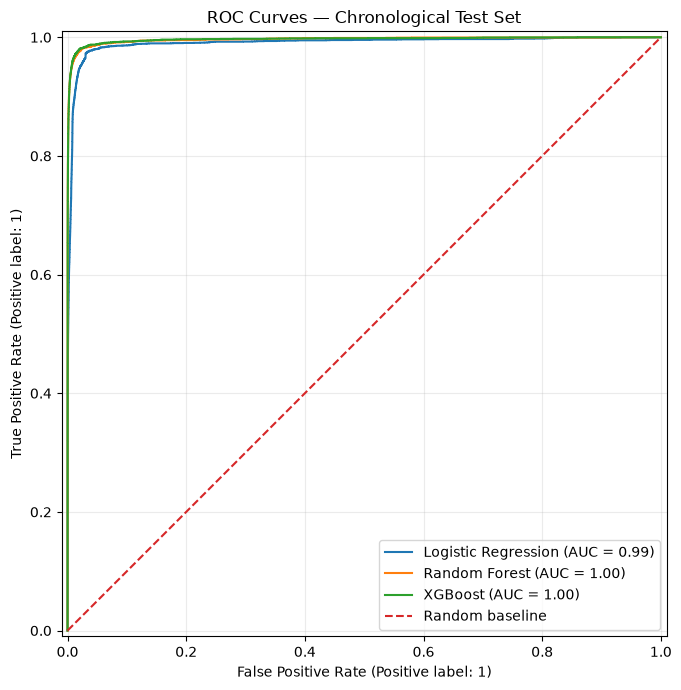

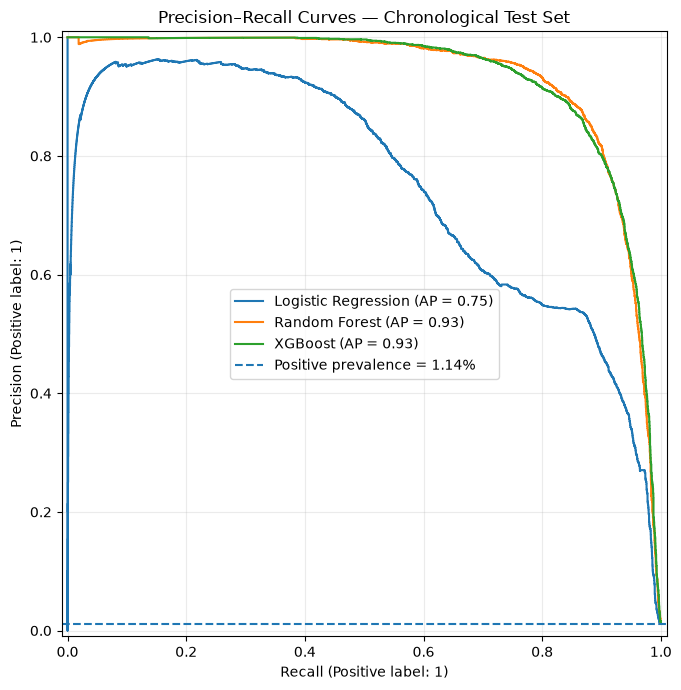

Saved ROC and precision-recall curves.


In [16]:

# ============================================
# 13. ROC AND PRECISION-RECALL CURVES
# ============================================

import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

models = {
    "Logistic Regression": logistic_test_prob,
    "Random Forest": rf_test_prob,
    "XGBoost": xgb_test_prob,
}

# ROC curves
fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in models.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curves — Chronological Test Set")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Precision-recall curves
fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in models.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

baseline = y_test.mean()
ax.axhline(
    baseline,
    linestyle="--",
    label=f"Positive prevalence = {baseline:.2%}"
)
ax.set_title("Precision–Recall Curves — Chronological Test Set")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved ROC and precision-recall curves.")


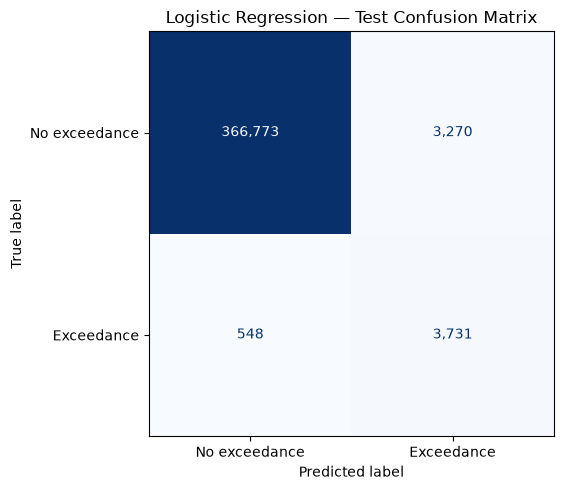

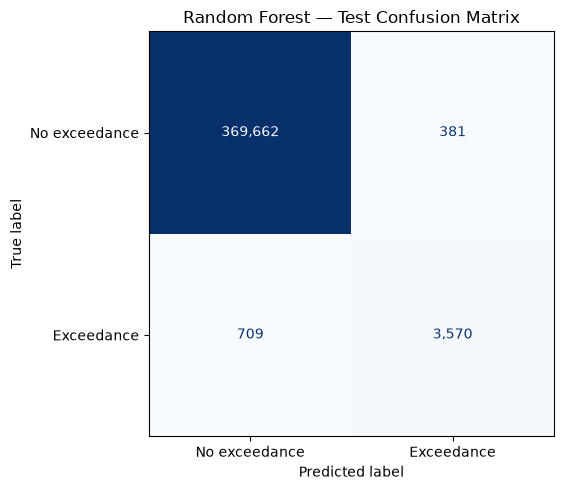

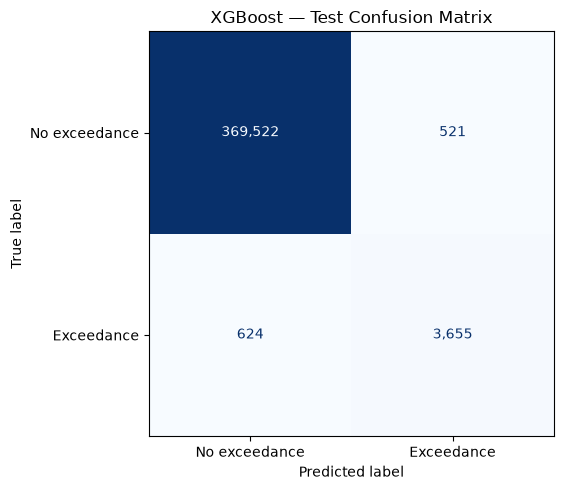

Saved all confusion-matrix heatmaps.


In [17]:

# ============================================
# 14. CONFUSION MATRIX HEATMAPS
# ============================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

predictions = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred,
}

for name, predictions_for_model in predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions_for_model,
        labels=[0, 1],
        display_labels=["No exceedance", "Exceedance"],
        cmap="Blues",
        values_format=",d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{name} — Test Confusion Matrix")
    fig.tight_layout()

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    fig.savefig(
        FIGURES_DIR / f"confusion_matrix_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Saved all confusion-matrix heatmaps.")


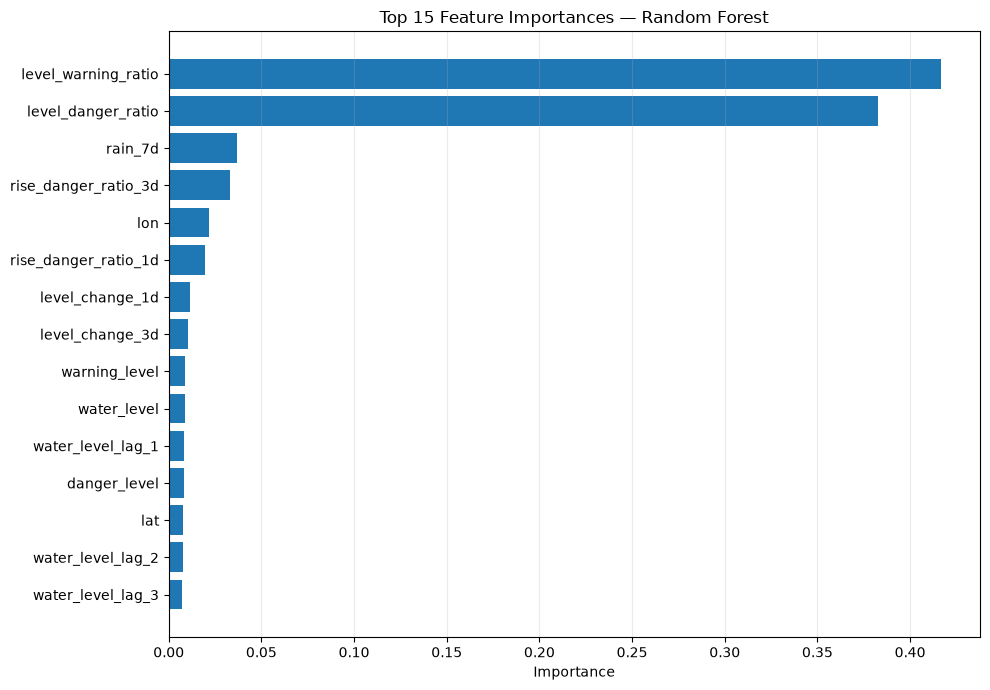

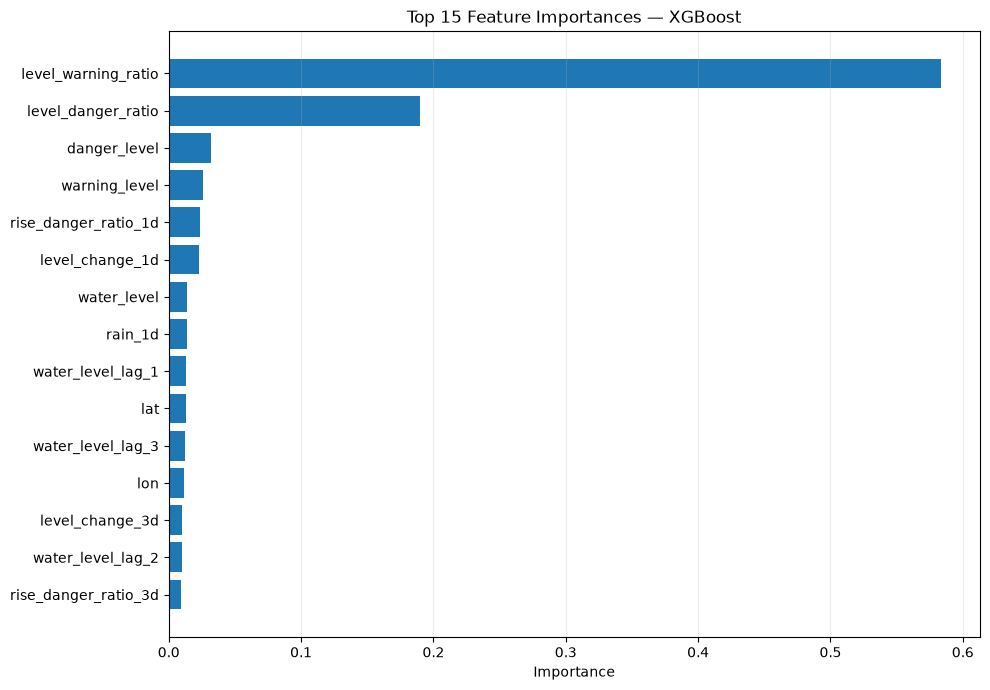


Random Forest — top 10 features:
             Feature  Importance
 level_warning_ratio    0.416864
  level_danger_ratio    0.382721
             rain_7d    0.036721
rise_danger_ratio_3d    0.032829
                 lon    0.021480
rise_danger_ratio_1d    0.019648
     level_change_1d    0.011642
     level_change_3d    0.010656
       warning_level    0.008972
         water_level    0.008565

XGBoost — top 10 features:
             Feature  Importance
 level_warning_ratio    0.583806
  level_danger_ratio    0.189806
        danger_level    0.031586
       warning_level    0.025544
rise_danger_ratio_1d    0.023610
     level_change_1d    0.022550
         water_level    0.013627
             rain_1d    0.013594
   water_level_lag_1    0.013354
                 lat    0.012963


In [18]:

# ============================================
# 15. FEATURE IMPORTANCE
# ============================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_feature_importance(model, model_name, feature_names):
    # Tree-based models expose feature_importances_
    if not hasattr(model, "feature_importances_"):
        raise AttributeError(
            f"{model_name} does not expose feature_importances_."
        )

    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False)

    importance.to_csv(
        TABLES_DIR
        / f"feature_importance_{model_name.lower().replace(' ', '_')}.csv",
        index=False
    )

    top_features = importance.head(15).sort_values("Importance")

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top_features["Feature"], top_features["Importance"])
    ax.set_title(f"Top 15 Feature Importances — {model_name}")
    ax.set_xlabel("Importance")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    filename = model_name.lower().replace(" ", "_")
    fig.savefig(
        FIGURES_DIR / f"feature_importance_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    return importance


rf_importance = plot_feature_importance(
    rf_model, "Random Forest", model_features
)

xgb_importance = plot_feature_importance(
    xgb_model, "XGBoost", model_features
)

print("\nRandom Forest — top 10 features:")
print(rf_importance.head(10).to_string(index=False))

print("\nXGBoost — top 10 features:")
print(xgb_importance.head(10).to_string(index=False))


In [19]:

# ============================================
# 16. ERROR ANALYSIS
# ============================================

error_models = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "XGBoost": xgb_test_pred,
}

error_summaries = []

for name, predictions in error_models.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    error_summaries.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "False Positive Rate": fp / (fp + tn) if fp + tn else 0,
        "False Negative Rate": fn / (fn + tp) if fn + tp else 0,
        "Missed Exceedances": fn,
        "Predicted Alerts": int(predictions.sum()),
    })

error_summary = pd.DataFrame(error_summaries)

error_summary.to_csv(
    TABLES_DIR / "error_analysis_summary.csv",
    index=False
)

print(error_summary.to_string(index=False))
print("\nSaved error analysis summary.")


              Model  True Negatives  False Positives  False Negatives  True Positives  False Positive Rate  False Negative Rate  Missed Exceedances  Predicted Alerts
Logistic Regression          366773             3270              548            3731             0.008837             0.128067                 548              7001
      Random Forest          369662              381              709            3570             0.001030             0.165693                 709              3951
            XGBoost          369522              521              624            3655             0.001408             0.145828                 624              4176

Saved error analysis summary.


In [20]:

# ============================================
# 17. RANDOM FOREST ERROR DETAILS
# ============================================

rf_errors = test_df[
    ["station_code", "date", "flood_next_day"]
].copy()

rf_errors["predicted_probability"] = rf_test_prob
rf_errors["predicted_class"] = rf_test_pred

rf_errors["error_type"] = np.select(
    [
        (rf_errors["flood_next_day"] == 1)
        & (rf_errors["predicted_class"] == 0),

        (rf_errors["flood_next_day"] == 0)
        & (rf_errors["predicted_class"] == 1),
    ],
    ["False Negative", "False Positive"],
    default="Correct"
)

rf_errors_only = rf_errors[
    rf_errors["error_type"] != "Correct"
].copy()

rf_errors_only.to_csv(
    TABLES_DIR / "random_forest_error_details.csv",
    index=False
)

print("Random Forest error counts:")
print(rf_errors_only["error_type"].value_counts())

print("\nSample missed exceedances:")
print(
    rf_errors_only[
        rf_errors_only["error_type"] == "False Negative"
    ].head(15).to_string(index=False)
)

print("\nSaved detailed error records.")


Random Forest error counts:
error_type
False Negative    709
False Positive    381
Name: count, dtype: int64

Sample missed exceedances:
station_code       date  flood_next_day  predicted_probability  predicted_class     error_type
   001-CDBNG 2026-08-01             1.0               0.240899                0 False Negative
   001-MDSIL 2026-07-08             1.0               0.747147                0 False Negative
 001-MGD4PTN 2025-10-04             1.0               0.091748                0 False Negative
 001-MGD5PTN 2025-08-02             1.0               0.605840                0 False Negative
 001-MGD5PTN 2026-09-02             1.0               0.807160                0 False Negative
  001-UBDDIB 2025-05-30             1.0               0.030677                0 False Negative
  001-UBDDIB 2025-05-31             1.0               0.859486                0 False Negative
0010-LYDAGRA 2025-07-31             1.0               0.884540                0 False Negative
 002-MGD

Validation shape: (446049, 17)
Validation dates: 2023-01-01 00:00:00 to 2024-12-31 00:00:00


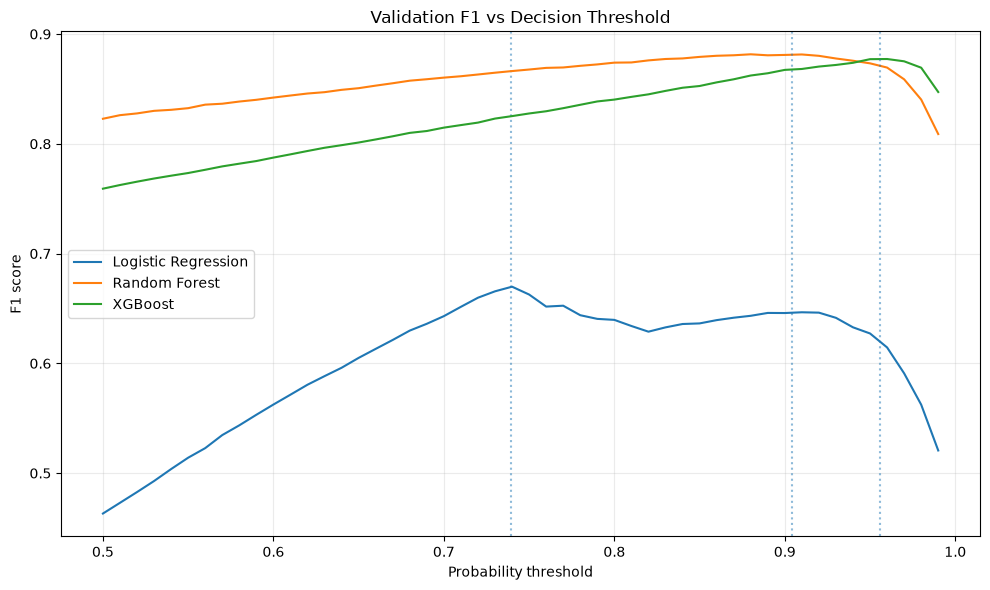


Best F1 within the examined threshold range:
              Model  Threshold  Precision   Recall       F1  Predicted_Alerts
Logistic Regression       0.74   0.539159 0.884140 0.669841              7827
      Random Forest       0.88   0.896641 0.866960 0.881551              4615
            XGBoost       0.96   0.894943 0.860256 0.877257              4588

Saved validation threshold analysis.


In [21]:

# ============================================
# 18. VALIDATION THRESHOLD ANALYSIS
# ============================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
)

# Reconstruct the validation set
val_df = ml_dataset[
    ml_dataset["date"].dt.year.isin([2023, 2024])
].copy()

X_val = val_df[model_features]
y_val = val_df["flood_next_day"].astype(int)

print("Validation shape:", X_val.shape)
print("Validation dates:", val_df["date"].min(), "to", val_df["date"].max())

# Generate validation probabilities
validation_models = {
    "Logistic Regression": (
        logistic_model,
        logistic_threshold
    ),
    "Random Forest": (
        rf_model,
        rf_threshold
    ),
    "XGBoost": (
        xgb_model,
        xgb_threshold
    ),
}

validation_probabilities = {}

for name, (model, _) in validation_models.items():
    validation_probabilities[name] = model.predict_proba(X_val)[:, 1]

# Evaluate several thresholds on validation data
thresholds = np.arange(0.50, 1.00, 0.01)
threshold_rows = []

for name, (_, locked_threshold) in validation_models.items():
    probabilities = validation_probabilities[name]

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "Predicted_Alerts": int(predictions.sum()),
            "Locked_Threshold": locked_threshold,
        })

threshold_results = pd.DataFrame(threshold_rows)

threshold_results.to_csv(
    TABLES_DIR / "validation_threshold_analysis.csv",
    index=False
)

# Plot F1 against threshold
fig, ax = plt.subplots(figsize=(10, 6))

for name in validation_models:
    subset = threshold_results[
        threshold_results["Model"] == name
    ]

    ax.plot(
        subset["Threshold"],
        subset["F1"],
        label=name
    )

    locked = validation_models[name][1]
    ax.axvline(
        locked,
        linestyle=":",
        alpha=0.5
    )

ax.set_title("Validation F1 vs Decision Threshold")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("F1 score")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "validation_f1_vs_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nBest F1 within the examined threshold range:")
print(
    threshold_results.loc[
        threshold_results.groupby("Model")["F1"].idxmax(),
        ["Model", "Threshold", "Precision", "Recall", "F1",
         "Predicted_Alerts"]
    ].to_string(index=False)
)

print("\nSaved validation threshold analysis.")


In [22]:

# ============================================
# 19. FINAL EVALUATION SUMMARY
# ============================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

locked_models = {
    "Logistic Regression": (logistic_test_prob, logistic_test_pred),
    "Random Forest": (rf_test_prob, rf_test_pred),
    "XGBoost": (xgb_test_prob, xgb_test_pred),
}

threshold_map = {
    "Logistic Regression": logistic_threshold,
    "Random Forest": rf_threshold,
    "XGBoost": xgb_threshold,
}

summary_rows = []

for name, (probabilities, predictions) in locked_models.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    summary_rows.append({
        "Model": name,
        "Threshold": threshold_map[name],
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "True_Negatives": tn,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "Predicted_Alerts": int(predictions.sum()),
    })

final_evaluation = pd.DataFrame(summary_rows)

final_evaluation.to_csv(
    TABLES_DIR / "final_test_evaluation.csv",
    index=False
)

print(final_evaluation.round(4).to_string(index=False))
print("\nSaved:", TABLES_DIR / "final_test_evaluation.csv")


              Model  Threshold  ROC_AUC  PR_AUC  Precision  Recall     F1  True_Negatives  False_Positives  False_Negatives  True_Positives  Predicted_Alerts
Logistic Regression     0.7394   0.9903  0.7514     0.5329  0.8719 0.6615          366773             3270              548            3731              7001
      Random Forest     0.9044   0.9962  0.9324     0.9036  0.8343 0.8676          369662              381              709            3570              3951
            XGBoost     0.9560   0.9965  0.9328     0.8752  0.8542 0.8646          369522              521              624            3655              4176

Saved: d:\01_PROJECTS\DS_AI\flood-prediction-india\reports\tables\final_test_evaluation.csv
